# Исследование стартапов

## Введение

### Цели и задачи проекта

**Цель проекта:** проанализировать закономерности финансирования стартапов на исторических данных и оценить перспективы выхода на рынок с покупкой и развитием компаний

<div> 
    <b>Задачи:</b> 
    <ol> 
        <li>Загрузить данные и ознакомиться с их содержанием, проверить корректность числовых и временных значений</li> 
        <li>Провести предобработку данных:
            <ol style="list-style-type: decimal;"> 
                <li>Обработать дубликаты и пропуски</li> 
                <li>Произвести оптимизацию типов данных</li> 
            </ol>
        </li> 
        <li>Провести исследовательский анализ данных:
            <ol style="list-style-type: decimal;"> 
                <li>Выделить группы компаний по срокам финансирования и сравнить их по количеству и объёму инвестиций</li> 
                <li>Классифицировать сегменты рынка на массовые, средние и нишевые и учесть это в дальнейшем анализе</li> 
                <li>Определить типичные и аномальные значения объёмов финансирования, исключить выбросы и ограничить период исследования</li> 
                <li>Сравнить популярность и объёмы разных типов финансирования</li> 
                <li>Проанализировать динамику раундов и объёмов инвестиций по годам, а также изменения в массовых сегментах рынка</li> 
                <li>Рассчитать долю возврата средств для разных типов финансирования и оценить её устойчивость</li> 
            </ol>
        </li> 
        <li>Сформулировать выводы по проведенному анализу и дать рекомендации по выходу на рынок в 2015 году</li> 
    </ol> 
</div>



### Описание данных

Для анализа поступили данные о компаниях, использующих финансирование. Данные представлены в виде двух датасетов

Датасет `cb_investments` содержит информацию о компаниях и состоявшемся финансировании

Описание датасета `cb_investments`
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.


Датасет `cb_returns` содержит информацию об объёмах возвратов по годам и типам финансирования в миллионах долларов

Описание датасета `cb_returns`
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.



## Загрузка данных и знакомство с ними

Импортируем библиотеки, которые будем использовать в дальнейшей работе для анализа и представления данных: `pandas`, `matplotlib`, `seaborn` и `phik`.

Установим библиотеку `phik`. Методы этой библиотеки помогают рассчитать продвинутые коэффициенты корреляции, при этом данная библиотека не предустановлена в среде, поэтому импортируем ее с помощью `install`. С помощью флага `-q` ограничим вывод логов, пропишем версию библиотеки, чтобы избежать ошибок совместимости 

In [1]:
!pip install -q phik==0.11.0

In [2]:
import pandas as pd
import numpy as np
#Загрузка библиотек для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns
# Загрузка библиотеки для расчета коэффициента корреляции
from phik import phik_matrix

Выгрузим данные датасетов `cb_investments` и `cb_returns` и сохраним их в переменных с идентичными названиями

In [3]:
cb_investments = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)

In [4]:
cb_returns = pd.read_csv("https://code.s3.yandex.net/datasets/cb_returns.csv", low_memory=False)

Выведем первые 5 строк таблиц

In [5]:
cb_investments.head(5)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
cb_investments['seed'].sum()

np.float64(10743940148.0)

Данные соответствуют описанию таблицы

In [7]:
cb_returns.head(5)

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


Данные соответствуют описанию таблицы

Ознакомимся с данными датафрейма `cb_investments` с помощью метода `info`: определим размеры таблицы, количество пропусков в столбцах и типы данных

In [8]:
cb_investments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Изучим, какие данные встречаются в столбцах `founded_at`, `founded_month`, `founded_quarter`, `first_funding_at`, `mid_funding_at`, `last_funding_at`, чтобы понять, **соответствуют ли данные типу `object`**

In [9]:
cb_investments[['founded_at', 'founded_month', 'founded_quarter', 'first_funding_at', 'mid_funding_at', 'last_funding_at']].dropna().head(5)

,founded_at,founded_month,founded_quarter,first_funding_at,mid_funding_at,last_funding_at
74,1903-01-01,1903-01,1903-Q1,2008-08-07,2008-08-07,2008-08-07
77,1906-01-01,1906-01,1906-Q1,2012-03-15,2012-03-15,2012-03-15
78,1906-01-01,1906-01,1906-Q1,2012-08-16,2012-08-16,2012-08-16
82,1908-01-01,1908-01,1908-Q1,2013-08-25,2013-08-25,2014-02-21
84,1910-01-01,1910-01,1910-Q1,2013-04-01,2013-04-01,2013-04-01


Подсчитаем абсолютное и относительное значение пропусков в столбцах таблицы

In [10]:
#абсолютное значение пропусков в столбцах таблицы
cb_investments.isnull().sum()

name                     4857
homepage_url             8305
category_list            8817
 market                  8817
 funding_total_usd       4856
status                   6170
country_code            10129
state_code              24133
region                  10129
city                    10972
funding_rounds           4856
participants            23821
founded_at              15740
founded_month           15812
founded_quarter         15812
founded_year            15740
first_funding_at         4856
mid_funding_at          24006
last_funding_at          4856
seed                     4856
venture                  4856
equity_crowdfunding      4856
undisclosed              4856
convertible_note         4856
debt_financing           4856
angel                    4856
grant                    4856
private_equity           4856
post_ipo_equity          4856
post_ipo_debt            4856
secondary_market         4856
product_crowdfunding     4856
round_A                  4856
round_B   

In [11]:
#относительное значение пропусков в столбцах таблицы в процентах
round(cb_investments.isnull().sum()/cb_investments.shape[0],3) * 100

name                     8.9
homepage_url            15.3
category_list           16.2
 market                 16.2
 funding_total_usd       8.9
status                  11.4
country_code            18.7
state_code              44.4
region                  18.7
city                    20.2
funding_rounds           8.9
participants            43.9
founded_at              29.0
founded_month           29.1
founded_quarter         29.1
founded_year            29.0
first_funding_at         8.9
mid_funding_at          44.2
last_funding_at          8.9
seed                     8.9
venture                  8.9
equity_crowdfunding      8.9
undisclosed              8.9
convertible_note         8.9
debt_financing           8.9
angel                    8.9
grant                    8.9
private_equity           8.9
post_ipo_equity          8.9
post_ipo_debt            8.9
secondary_market         8.9
product_crowdfunding     8.9
round_A                  8.9
round_B                  8.9
round_C       

Датасет `cb_investments` состоит из **40 столбцов** и **54294 строк**. 
Полсе первичного анализа можно сделать следующие выводы:
- Названия столбцов не приведены к единому стилю: столбцы `market` и `funding_total_usd` содержат лишние пропуски. Столбцы `round_A` - `round_H` не приведены к стилю `snake_case`
- Пропуски встречаются во всех столбцах таблицы. Значение пропусков варируется **от 8.9% до 44.4%**. Наибольшие количество пропусков (44.4% или 24133 строки) в столбце `state_code`. 
- Наличие пропусков **можно объяснить следующими факторами:** пропуски в столбцах `seed`(сумма инвестиций на посевной стадии) или `equity_crowdfunding`(сумма, привлечённая через долевой краудфандинг) - компания не привлекала инвестиций на посевной стадии или через долевой краудфаринг. Спецификой привлечения финансирования можно объяснить пропуски в столбцах, содержащих данные о количестве средств на разных этапах: `round_A` - `round_H`. Поэтому мы **не будем заменять пропуски** в этих столбцах средним арифметическим, модой или медианой, также не станем заполнять значениями-индикаторами. 
- Наличие пропусков в столбцах с названием компании, адресом сайта, числом участников в раундах финансирования **не влияет на вопрос исследования.** Без этих данных **возможно дать рекомендации** по выходу на рынок инвестирования стартапов в определенных нишах, помимо этого, их невозможно заменить какими-либо значениями, оставим их без изменений. 
- Для исследования важно знать отрасль, в которой работает компания, поэтому пропуски в столбцах `category_list` и `market` являются критическими важными. Отсутствующие значения заменим на "без категории" и сможем добавить эти данные в анализ
- **24 столбца** имеют тип данных `float(64)`, когда как **16 столбцов** имеют тип `object`. Мы проверили, какие данные содержатся в столбцах с типом данных `object`. Выяснилось, что столбцы `founded_at`, `founded_month`, `founded_quarter`, `first_funding_at`, `mid_funding_at`, `last_funding_at` содержат данные, которые удобно преобразовать в тип данных `datetime`. При измении типа данных мы сможем посмотреть выборки за определеный год, сократим количество занимаемой оперативной памяти и сможем применять удобные свойства типа `datetime`

Ознакомимся с данными датафрейма `cb_returns` с помощью метода `info`: определим размеры таблицы, количество пропусков в столбцах и типы данных

In [12]:
cb_returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


In [13]:
cb_returns

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
1,2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
3,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
4,2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
5,2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
6,2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
7,2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
8,2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00
9,2009,160.21,2501.29,0.18,37.50,2.25,394.10,97.21,0.0,203.70,76.76,0.00,0.12,0.02


Датасет `cb_returns` состоит из **14 столбцов** и **15 строк**. 
- Названия столбцов соответствуют стилю `snake_case`
- Все столбцы заполнены, датасет не содержит пропусков
- Тип данных `float64` можно оптимизировать, так как он является избыточным для хранения вещественных чисел, содержащих два знака после запятой

## Предобработка данных

Приведем названия столбцов датафрейма `cb_investments` к стилю `snake_case`

Для этого удалим лишние пропуски в названии столбцов `market` и `funding_total_usd`

In [14]:
cb_investments.columns = cb_investments.columns.str.strip()

In [15]:
cb_investments.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

Приведем названия столбцов `round_A` - `round_H` к стилю `snake_case`. Для этого приведем все составляющие названия в нижний регистр. 

In [16]:
# Приводим все составляющие названия столбцов к нижнему регистру 
cb_investments.columns = cb_investments.columns.str.lower()

In [17]:
cb_investments.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_a', 'round_b',
       'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h'],
      dtype='object')

Мы привели названия столбцов к стилю `snake_case` и убедились в корректности преобразования

Уберем в столбце `funding_total_usd` выделение разрядов и приведем его к числовому типу.

Для этого заменим пробелы на пустые строки

In [18]:
cb_investments['funding_total_usd'] = cb_investments['funding_total_usd'].str.replace(",", '')

Далее приведем к числовому типу. Так как в столбце встречаются значения '-', то добавим параметр `errors='coerce'`, при котором исключения будут записываться как Nan

In [19]:
cb_investments['funding_total_usd'] = pd.to_numeric(cb_investments['funding_total_usd'], errors='coerce', downcast='integer')

In [20]:
cb_investments['funding_total_usd'].dtype

dtype('float64')

In [21]:
cb_investments['funding_total_usd'].value_counts()

funding_total_usd
1000000.0    925
500000.0     761
100000.0     749
40000.0      680
2000000.0    623
            ... 
474063.0       1
1247816.0      1
94126.0        1
1548150.0      1
560248.0       1
Name: count, Length: 14616, dtype: int64

In [22]:
cb_investments['funding_total_usd'].isna().sum()

np.int64(13387)

Обработаем типы данных в столбцах, которые хранят значения даты и времени

In [23]:
column_to_datetime = ['founded_at', 'founded_month', 'founded_quarter', 'first_funding_at', 'mid_funding_at', 'last_funding_at']

In [24]:
for column in cb_investments.columns:
    if column in column_to_datetime:
        cb_investments[column] = pd.to_datetime(cb_investments[column], errors='coerce')

C:\Users\kate\AppData\Local\Temp\ipykernel_11768\42477741.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cb_investments[column] = pd.to_datetime(cb_investments[column], errors='coerce')
C:\Users\kate\AppData\Local\Temp\ipykernel_11768\42477741.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cb_investments[column] = pd.to_datetime(cb_investments[column], errors='coerce')


Проверим, что данные приведены к нужному типу

In [25]:
cb_investments[column_to_datetime].dtypes

founded_at          datetime64[ns]
founded_month       datetime64[ns]
founded_quarter     datetime64[ns]
first_funding_at    datetime64[ns]
mid_funding_at      datetime64[ns]
last_funding_at     datetime64[ns]
dtype: object

В датасете `cb_returns` сделаем столбец `year` индексом всего датасета

In [26]:
cb_returns = cb_returns.set_index('year')

In [27]:
cb_returns.index

Index([2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011,
       2012, 2013, 2014],
      dtype='int64', name='year')

Пропуски в столбце `market` заменим на значения 'без категории' 

In [28]:
cb_investments['market'] = cb_investments['market'].fillna('без категории')

Проверим наличие пропусков в столбце после его заполнения

In [29]:
cb_investments['market'].isna().sum()

np.int64(0)

Нормализуем значения столбца `market`: избавимся от лишних пропусков, переведем в нижний регистр

In [30]:
cb_investments['market'] = cb_investments['market'].str.strip()

In [31]:
cb_investments['market'] = cb_investments['market'].str.lower()

In [32]:
cb_investments['market']

0                education
1            без категории
2        business services
3                education
4                education
               ...        
54289        без категории
54290        без категории
54291        без категории
54292        без категории
54293        без категории
Name: market, Length: 54294, dtype: object

Обработаем полные дубликаты в данных и пропуски в `funding_total_usd`. Избавимся от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании

С помощью метода `duplicated`определим количество дубликатов 

In [33]:
cb_investments.duplicated(keep=False).sum()

np.int64(4856)

Удалим явные дубликаты, сохраним очищенные данные в новый датафрейм `cb_investments_filtered`, и проверим корректность действия с помощью повторного вызова метода `drop_duplicates`

In [34]:
cb_investments_filtered = cb_investments.drop_duplicates().copy()

In [35]:
cb_investments_filtered.duplicated(keep=False).sum()

np.int64(0)

Для обработки пропусков в столбце `funding_total_usd`суммируем данные по инвестициям в других столбцах (`seed`, `venture`, `equity_crowdfunding`,`undisclosed`,`convertible_note`,`debt_financing`,`angel`,`grant`,`private_equity`,
`post_ipo_equity`,`post_ipo_debt`,`secondary_market`,`product_crowdfunding`). Если и эти столбцы не будут содержать данных, то мы избавимся от этих строк

Создадим список всех столбцов для суммирования

In [36]:
investment_cols = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note',
    'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity',
    'post_ipo_debt', 'secondary_market', 'product_crowdfunding'
]

Просуммируем ненулевые значения столбцов из списка `investment_cols` для тех строк, в которых `funding_total_usd` хранит Null, и сохраним получившиеся значения в серии `calculated_totals`

Будем использовать проверку, что хотя бы одно значение из списка `investment_cols` отлично от Null

In [37]:
calculated_totals = cb_investments_filtered.loc[cb_investments_filtered['funding_total_usd'].isna(), investment_cols].sum(axis=1, min_count=1)


In [38]:
cb_investments_filtered['funding_total_usd'] = cb_investments_filtered['funding_total_usd'].fillna(calculated_totals)


In [39]:
cb_investments_filtered = cb_investments_filtered.dropna(subset=['funding_total_usd']).copy()


Оказалось, что данная проверка не помогает восстановить значение в столбце `funding_total_usd`, так как вместо NaN столбцы содержали 0

In [40]:
calculated_totals

13       0.0
15       0.0
19       0.0
27       0.0
35       0.0
        ... 
49421    0.0
49425    0.0
49426    0.0
49431    0.0
49438    NaN
Length: 8532, dtype: float64

Поэтому нам нужно отфильтровать датасет и оставить только те строки, значения которых в столбце `funding_total_usd` больше 0

In [41]:
cb_investments_filtered = cb_investments_filtered.loc[cb_investments_filtered['funding_total_usd'] > 0]

In [42]:
cb_investments_filtered['funding_total_usd'].value_counts()

funding_total_usd
1000000.0    925
500000.0     761
100000.0     749
40000.0      680
2000000.0    623
            ... 
474063.0       1
1247816.0      1
94126.0        1
1548150.0      1
560248.0       1
Name: count, Length: 14616, dtype: int64

Заполним пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмём приблизительно середину интервала между этими двумя датами.

In [43]:
cb_investments_filtered['mid_funding_at'].isna().sum()

np.int64(13676)

До заполнения пропусков столбец `mid_funding_at` содержал **19150** пропусков

In [44]:
mid_date = (cb_investments_filtered['first_funding_at'] + (cb_investments_filtered['last_funding_at'] - cb_investments_filtered['first_funding_at']) / 2)

In [45]:
cb_investments_filtered['mid_funding_at'] = cb_investments_filtered['mid_funding_at'].fillna(mid_date)

Проверим тип заполненного столбца `mid_funding_at`

In [46]:
cb_investments_filtered['mid_funding_at'].dtype

dtype('<M8[ns]')

In [47]:
cb_investments_filtered['mid_funding_at'].isna().sum()

np.int64(1)

После заполнения пропусков столбец `mid_funding_at` 1 пропуск

Определим, какой процент данных был отброшен

In [48]:
round(((cb_investments.shape[0] - cb_investments_filtered.shape[0]) / cb_investments.shape[0]) * 100,2)

24.66

Оценим полноту данных и сделаем предварительный вывод о том, достаточно ли данных для решения задач проекта

Для оценки найдем относительное количество пропусков в очищенном датафрейме `cb_investments_filtered`

In [49]:
round(cb_investments_filtered.isnull().sum()/cb_investments_filtered.shape[0],3) * 100

name                     0.0
homepage_url             5.7
category_list            6.1
market                   0.0
funding_total_usd        0.0
status                   2.7
country_code             9.3
state_code              37.4
region                   9.3
city                    11.0
funding_rounds           0.0
participants            33.2
founded_at              21.3
founded_month           21.4
founded_quarter         21.4
founded_year            21.3
first_funding_at         0.0
mid_funding_at           0.0
last_funding_at          0.0
seed                     0.0
venture                  0.0
equity_crowdfunding      0.0
undisclosed              0.0
convertible_note         0.0
debt_financing           0.0
angel                    0.0
grant                    0.0
private_equity           0.0
post_ipo_equity          0.0
post_ipo_debt            0.0
secondary_market         0.0
product_crowdfunding     0.0
round_a                  0.0
round_b                  0.0
round_c       

Представленные данные полны. После удаления явных дубликатов и строк, содержащих нулевые значения в столбце `funding_total_usd`, мы получили новый датафрейм `cb_investments_filtered`. 

Ключевые показатели финансирования (столбцы `funding_total_usd` и `funding_rounds`) имеют 0.0% пропусков, что гарантирует высокую точность при анализе инвестиционных объемов. Столбец `market`, отвечающий за классификацию рынков полностью заполнен (доля пропусков в столбце `category_list` не превышает 6.1%), что позволяет корректно разделить сегменты на массовые и нишевые. Наличие пропусков в географических данных (9.3% в `country_code`) и составе участников (`participants` — 33.2%) является естественной спецификой венчурного рынка (ввиду непубличности ряда сделок) и не препятствует выявлению глобальных инвестиционных закономерностей. Датасет полностью готов к дальнейшему исследованию.

## Инжиниринг признаков

### Группы по срокам финансирования

Разделим все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируем соотношение этих групп, создав два графика:

* По количеству компаний: покажем, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: отобразим, какую долю от общего объёма привлечённых средств получила каждая группа.

In [50]:
cb_investments_filtered.loc[cb_investments_filtered['funding_rounds'] == 1, 'funding_category'] = 'single round'

Для избежания ошибок при определении группы финансирования проверим выполнение двух условий: количество раундов превышает 1 и разница между финансированием меньше года. В противном случае компании с единичном финансированием будут определены в группу со сроком финансирования до года

In [51]:
mask_under_year = (
    ((cb_investments_filtered['last_funding_at'] - cb_investments_filtered['first_funding_at']).dt.days <= 365) & 
    (cb_investments_filtered['funding_rounds'] > 1)
)
cb_investments_filtered.loc[mask_under_year, 'funding_category'] = 'under a year'

In [52]:
cb_investments_filtered.loc[(cb_investments_filtered['last_funding_at'] - cb_investments_filtered['first_funding_at']).dt.days > 365, 'funding_category'] = 'over a year'

Убедимся в корректности заполнения добавленного столбца `funding_category` с помощью подсчета количества значений

In [53]:
cb_investments_filtered['funding_category'].value_counts()

funding_category
single round    24113
over a year     12291
under a year     4501
Name: count, dtype: int64

Визуализируем соотношения групп. На первом графике отобразим, какой процент от общего числа компаний относится к каждой из трех групп

In [54]:
funding_group_share = cb_investments_filtered['funding_category'].value_counts() / cb_investments_filtered['funding_rounds'].size

In [55]:
funding_group_share

funding_category
single round    0.589459
over a year     0.300462
under a year    0.110030
Name: count, dtype: float64

Создадим словарь, содержащий цвета для отображения определенной категории на графике

In [56]:
category_colors = {
    'single round': '#1f77b4', 
    'under a year': '#ff7f0e',  
    'over a year': '#2ca02c'    
}

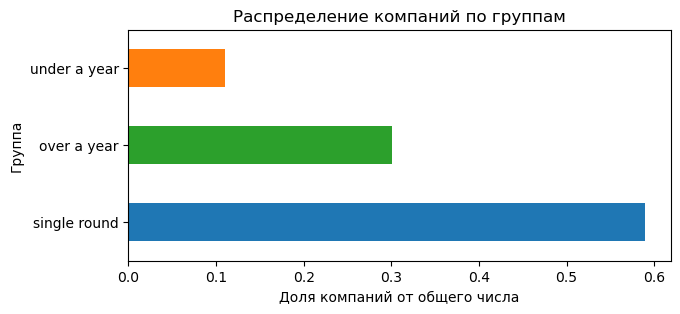

In [57]:
plt.figure(figsize=(7, 3))

current_colors = [category_colors[group] for group in funding_group_share.index]
funding_group_share.plot(kind="barh", x="category", legend=False, title="Распределение компаний по группам", color=current_colors)

plt.xlabel('Доля компаний от общего числа')
plt.ylabel('Группа')

plt.show()

58% компаний, представленных в датафрейме, привлекали единичное финансирование. Доля этих компаний значительно превышает компании со сроком финансирования до года, таких компаний 30%. 11% занимают компании со сроком финансирования более года 

Далее отобразим, какую долю от общего объёма привлечённых средств получила каждая группа

In [58]:
total_group_share = cb_investments_filtered.groupby('funding_category')['funding_total_usd'].agg('sum') / cb_investments_filtered['funding_total_usd'].sum()

In [59]:
total_group_share

funding_category
over a year     0.618664
single round    0.306182
under a year    0.075101
Name: funding_total_usd, dtype: float64

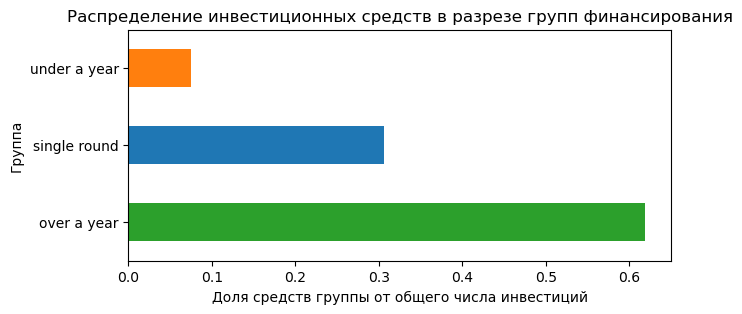

In [60]:
plt.figure(figsize=(7,3))

current_colors = [category_colors[group] for group in total_group_share.index]
total_group_share.plot(kind="barh", x="category", legend=False, title="Распределение инвестиционных средств в разрезе групп финансирования", color=current_colors)

plt.xlabel('Доля средств группы от общего числа инвестиций')
plt.ylabel('Группа')

plt.show()

Распределение инвестиционных средств сильно отличается от распределения компаний по группам. Несмотря на то, что группа `over a year` является второй по численности **(30% компаний)**, именно она привлекла наибольшую долю средств — **61%.**

Самая многочисленная группа `single round` (в нее входит **58,9% всех компаний**) аккумулировала лишь **30%** инвестиций. Наименьший объем средств **(7%)** приходится на группу `under a year`, которая также является самой малочисленной по количеству компаний **(11%)**

### Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитаем, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесем к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесем к средним, а сегменты до 35 компаний отнесем к нишевым. Рассчитаем, сколько сегментов попадает в каждую из категорий.

In [61]:
market_counts = cb_investments_filtered['market'].value_counts()

In [62]:
mass_markets_list = market_counts[(market_counts > 120)].index

In [63]:
mass_market_mask = cb_investments_filtered['market'].isin(mass_markets_list)
cb_investments_filtered.loc[mass_market_mask, 'market_segment'] = 'mass market'

In [64]:
middle_markets_list = market_counts[(market_counts >= 35) & (market_counts <= 120)].index

In [65]:
market_mask = cb_investments_filtered['market'].isin(middle_markets_list)
cb_investments_filtered.loc[market_mask, 'market_segment'] = 'middle market'

In [66]:
niche_markets_list = market_counts[(market_counts < 35)].index

In [67]:
niche_markets_mask = cb_investments_filtered['market'].isin(niche_markets_list)
cb_investments_filtered.loc[niche_markets_mask, 'market_segment'] = 'niche market'

Для проверки корректности заполнения добавленного столбца `market segment` подсчитаем количество того или значения

In [68]:
cb_investments_filtered['market_segment'].value_counts()

market_segment
mass market      36236
middle market     3841
niche market       830
Name: count, dtype: int64

Рассчитаем, сколько сегментов попадает в каждую категорию

In [69]:
count_segment = cb_investments_filtered.groupby("market_segment")['market'].nunique()

In [70]:
count_segment

market_segment
mass market       49
middle market     57
niche market     289
Name: market, dtype: int64

Построим график распределения количества компаний в сегментах и отобразим на нём разделение на нишевые и средние сегменты.

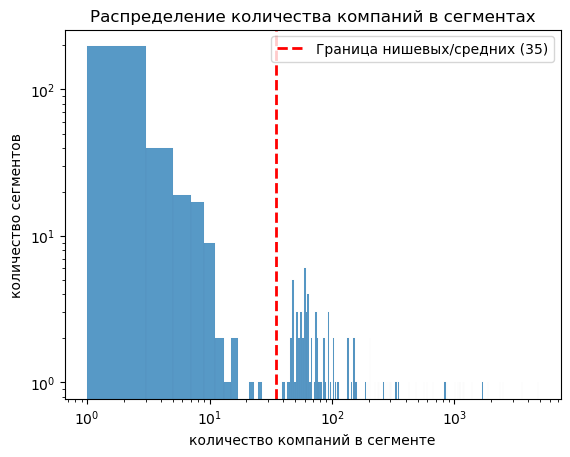

In [71]:
sns.histplot(x=market_counts, bins=40, binwidth=2)
plt.axvline(35, color='red', linestyle='--', linewidth=2, label='Граница нишевых/средних (35)')
plt.title('Распределение количества компаний в сегментах')
plt.xlabel('количество компаний в сегменте')
plt.ylabel('количество сегментов')
plt.yscale('log')
plt.xscale('log')
plt.legend()
plt.show()

В качестве масштаба для обеих осей была выбрана логарифмическая шкала, благодаря чему на диаграмме удалось отобразить весь спектр сегментов — от мелких до самых крупных. Вертикальная граница наглядно демонстрирует, что в датасете превалируют нишевые сегменты (в которых сосредоточено менее 35 компаний).

Оставим в столбце `market` только массовые сегменты. Для остальных сегментов заменим значения на заглушки — `niche` для нишевых и `mid` для средних. Сохраним копию измененного датасета.

In [72]:
cb_investments_filtered.loc[cb_investments_filtered['market_segment'] == 'middle market', 'market'] = 'mid'

In [73]:
cb_investments_filtered.loc[cb_investments_filtered['market_segment'] == 'niche market', 'market'] = 'niche'

In [74]:
cb_investments_filtered.loc[cb_investments_filtered['market'] == 'niche', 'market'].count()

np.int64(830)

## Работа с выбросами и анализ

###  Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оценим, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Далее укажим интервал, в котором лежат типичные значения.

In [75]:
cb_investments_filtered['funding_total_usd'].describe()

count    4.090700e+04
mean     1.591253e+07
std      1.686788e+08
min      1.000000e+00
25%      3.500000e+05
50%      2.000000e+06
75%      1.000000e+07
max      3.007950e+10
Name: funding_total_usd, dtype: float64

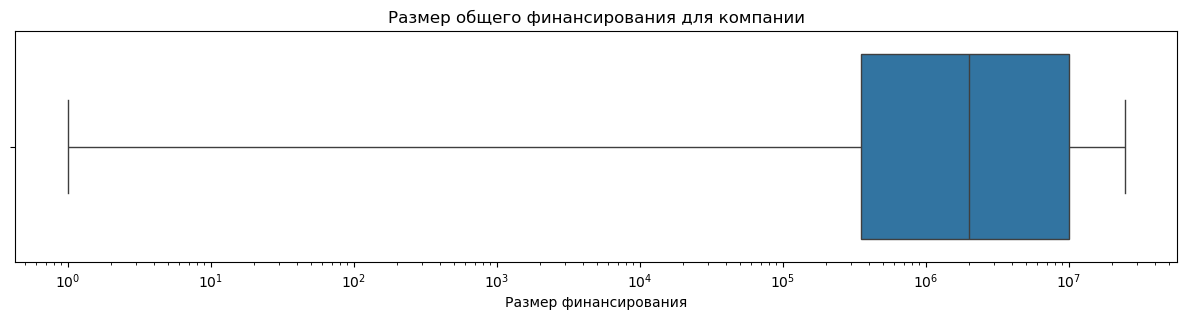

In [76]:
plt.figure(figsize=(15, 3))
sns.boxplot(data=cb_investments_filtered, x='funding_total_usd', showfliers=False)
plt.title('Размер общего финансирования для компании')
plt.xscale('log')
plt.xlabel('Размер финансирования')
plt.show()

На графике представлено распределение размеров финансирования по логарифмической шкале. «Ящик» на диаграмме (межквартильный размах) отображает типичные значения. Согласно рассчитанным квартилям (25-й и 75-й перцентили), **интервал типичного финансирования лежит в диапазоне от 250 000 до 5 000 000 долларов**, а медиана составляет **1 310 000 долларов**. 

Значения, выходящие за границы «усов», являются выбросами. Исходя из рассчитанных квартилей (Q1 = 250 000, Q3 = 5 000 000) и межквартильного размаха (IQR = 4 750 000), верхняя граница нормы для всего рынка составляет **12 125 000 долларов** (Q3 + 1.5 * IQR). 

Однако, поскольку масштабы финансирования в разных отраслях кардинально отличаются, для более точного и объективного поиска аномалий мы рассчитаем эти границы индивидуально для каждого сегмента рынка ниже.

Определим компании с аномальным объёмом общего финансирования — используем метод IQR отдельно по каждому сегменту. 

In [77]:
segment_stats = cb_investments_filtered.groupby('market')['funding_total_usd'].agg(
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)

Для каждого сегмента рассчитаем значение границы левого уса. Значения, выходящие за границы левого уса, являются аномальными.

In [78]:
segment_stats['IQR'] = segment_stats['Q3'] - segment_stats['Q1']
segment_stats['upper_bound'] = segment_stats['Q3'] + 1.5 * segment_stats['IQR']

Сопоставим каждой компании границы усов в соответствии с их сегментом

In [79]:
cb_investments_filtered['upper_bound'] = cb_investments_filtered['market'].map(segment_stats['upper_bound'])

Создадим новый столбец `diff_from_bound`, в котором будем хранить разницу между `funding_total_usd` и `upper_bound`

In [80]:
cb_investments_filtered['diff_from_bound'] = cb_investments_filtered['funding_total_usd'] - cb_investments_filtered['upper_bound']

Определим компании с аномальным значением финансирования для сегмента, к которому они относятся 

In [81]:
funding_outliers = cb_investments_filtered.loc[
    cb_investments_filtered['funding_total_usd'] > cb_investments_filtered['upper_bound'], 
    ['name', 'market', 'funding_total_usd', 'upper_bound', 'diff_from_bound']
]

In [82]:
funding_outliers

,name,market,funding_total_usd,upper_bound,diff_from_bound
0,Harvard University,education,90000000.0,11821079.25,78178920.75
5,Xavier University,без категории,19000000.0,5418268.00,13581732.00
6,Tulane University,education,12000000.0,11821079.25,178920.75
8,"Virginia Commonwealth University, Richmond",без категории,6000000.0,5418268.00,581732.00
10,VideoSurf,hardware + software,28000000.0,26792376.25,1207623.75
...,...,...,...,...,...
49415,Baedal Minjeok,без категории,36000000.0,5418268.00,30581732.00
49418,Genomics,без категории,16200000.0,5418268.00,10781732.00
49428,Ascendis Pharma,без категории,60000000.0,5418268.00,54581732.00
49432,Moko,без категории,8100000.0,5418268.00,2681732.00


In [83]:
funding_outliers = funding_outliers.sort_values(by='diff_from_bound', ascending=False)

Чтобы понять, где чаще всего встречаются аномальные объемы финансирования, выделим `Топ-15 сегментов` по абсолютному количеству компаний с аномальным финансированием.


Далее для этих сегментов рассчитаем долю компаний с аномальным объемом финансирования от общего числа компаний сегмента.

Такой подход позволит увидеть, в каких крупных сегментах аномалии - это редкость, а в каких они встречаются достаточно часто

Топ-15 сегментов по количеству компаний с аномальным объемом финансирования

In [84]:
top15_abs = funding_outliers['market'].value_counts().head(15)

Рассчет доли компаний с аномальным объемом финансирования от общего числа компаний

In [85]:
relative_anomalies = (funding_outliers['market'].value_counts() / cb_investments_filtered['market'].value_counts()) * 100

In [86]:
relative_anomalies

market
advertising             12.285456
analytics               12.293853
apps                    14.349776
automotive              14.193548
big data                15.333333
biotechnology           10.640669
clean technology        12.796610
cloud computing         16.447368
consulting              16.618911
curated web             11.931483
design                  11.111111
e-commerce              14.415863
education               13.270142
enterprise software     10.572049
entertainment           16.666667
fashion                 13.201320
finance                 12.560386
games                   10.474485
hardware + software     11.581921
health and wellness     12.943872
health care             10.801688
hospitality             13.095238
internet                15.352697
manufacturing           10.570470
marketplaces            15.306122
medical                 13.907285
messaging               12.881356
mid                     14.475397
mobile                  13.182594
music  

Добавим в датасет `funding_outliers` новый столбец `share` с долей компании

In [87]:
funding_outliers['share'] = funding_outliers['market'].map(relative_anomalies)

In [88]:
funding_outliers['share']

623      13.182594
48499    12.560386
7074     15.352697
1432     14.902117
295      14.475397
           ...    
27999    13.907285
12978    11.931483
3164     11.970075
7263     13.182594
23546    14.415863
Name: share, Length: 5244, dtype: float64

Построим датафрейм `top_analysis`, содержащий название сегмента, абсолютное количество компаний с аномальным объемом финансирования и долей этого числа компаний от общего числа компаний сегмента

In [89]:
top_analysis = pd.DataFrame({
    'Аномалий (шт.)': top15_abs,
    'Доля (%)': relative_anomalies[top15_abs.index]
})

In [90]:
top_analysis

,Аномалий (шт.),Доля (%)
market,,
software,576,11.970075
mid,556,14.475397
biotechnology,382,10.640669
без категории,373,14.902117
mobile,309,13.182594
e-commerce,269,14.415863
curated web,202,11.931483
clean technology,151,12.796610
enterprise software,146,10.572049


In [91]:
top_analysis.index

Index(['software', 'mid', 'biotechnology', 'без категории', 'mobile',
       'e-commerce', 'curated web', 'clean technology', 'enterprise software',
       'social media', 'advertising', 'niche', 'health care',
       'hardware + software', 'games'],
      dtype='object', name='market')

В ходе анализа не выявлено сегмента с явно доминирующей долей аномалий (выбросов) по сравнению с остальными. В топ-15 сегментов по абсолютному количеству аномалий относительная доля таких компаний варьируется в узком диапазоне — от 10% до 15%.

Это позволяет сделать вывод, что наличие аномально крупных раундов является системной особенностью рынка, а не спецификой одной отрасли. При этом безусловным лидером по абсолютному числу таких компаний является Software (576 компаний) и Mid-сегмент (556 компаний), что объясняется высокой концентрацией бизнеса именно в этих сферах. Остальные 13 сегментов (Bio, Mobile, E-commerce и др.) показывают стабильную долю аномалий, что говорит о зрелости и равномерности распределения капитала в них.

In [92]:
relative_anomalies.sort_values(ascending=False)

market
real estate             17.204301
entertainment           16.666667
consulting              16.618911
search                  16.494845
cloud computing         16.447368
photography             16.176471
saas                    16.176471
technology              15.966387
video                   15.957447
niche                   15.903614
travel                  15.454545
networking              15.384615
internet                15.352697
big data                15.333333
marketplaces            15.306122
без категории           14.902117
mid                     14.475397
e-commerce              14.415863
apps                    14.349776
automotive              14.193548
medical                 13.907285
sports                  13.725490
social media            13.559322
news                    13.289037
education               13.270142
fashion                 13.201320
mobile                  13.182594
hospitality             13.095238
health and wellness     12.943872
messagi

In [93]:
cb_investments_filtered.loc[cb_investments_filtered['market'] == 'tourism', 'name'].count()

np.int64(0)

Если смотреть на относительную долю аномалий без учета размера выборки, в лидеры выбиваются узкие сегменты (`tourism`, `kids`, `utilities`). Однако проверка показывает, что в каждом из них всего по 4 компании, и всего одна из них является выбросом (1 из 4 = 25%). Поэтому для объективной оценки мы рассматривали только крупные сегменты (Топ-15 по абсолютному числу аномалий)

Далее непосредственно рассмотрим сами компании с аномальным объемом финансирования в разрезе их сегмента

Выключим экспонициальное отображение значений для простоты восприятия значений

In [94]:
pd.set_option('display.float_format', lambda x: f'{x:,.0f}')

In [95]:
funding_outliers.sort_values(by='diff_from_bound', ascending=False).head(15)

,name,market,funding_total_usd,upper_bound,diff_from_bound,share
623,Verizon Communications,mobile,"30,079,503,000","18,785,938","30,060,717,062",13
48499,Sberbank,finance,"5,800,000,000","32,886,746","5,767,113,254",13
7074,Clearwire,internet,"5,700,000,000","12,125,000","5,687,875,000",15
1432,Charter Communications,без категории,"5,162,513,431","5,418,268","5,157,095,163",15
295,First Data Corporation,mid,"3,500,000,000","19,250,000","3,480,750,000",14
47589,COFCO,без категории,"3,200,000,000","5,418,268","3,194,581,732",15
9206,sigmacare,health and wellness,"2,600,000,000","18,889,900","2,581,110,100",13
8059,Facebook,social media,"2,425,700,000","7,312,500","2,418,387,500",14
12693,Carestream,biotechnology,"2,400,000,000","52,829,176","2,347,170,824",11
13528,Flipkart,mid,"2,351,140,000","19,250,000","2,331,890,000",14


Компанией лидером по разнице между средним значением финансирования в сегменте и общим значением финансирования стала `Verizon Communication` из сегмента `mobile`(`diff_from_bound` - 30 060 717 062). На втором месте распложился `Sberbank` из сегмента `finance` (`diff_from_bound` - 5 767 113 254), на третьем - `Clearwire` из сегмента `internet` (`diff_from_bound` - 5 687 875 000).

Треть топа (5 из 15 компаний) занимает сегмент mid (средний бизнес).

### Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверим насколько полные данные за 2014 год хранятся в датасете

Сформируем датафрейм `data_2014`, отфильтровав компании по дате последнего финансирования (`last_funding_at`), оставив только сделки 2014 года.
    

In [96]:
data_2014 = cb_investments_filtered[cb_investments_filtered['last_funding_at'].dt.year == 2014]

Подсчитаем количество сделок по месяцам

In [97]:
months_2014 = data_2014['last_funding_at'].dt.month.value_counts().sort_index()

In [98]:
months_2014

last_funding_at
1     1178
2      947
3     1072
4     1077
5     1036
6     1229
7     1254
8     1064
9     1135
10    1139
11     732
12      52
Name: count, dtype: int64

Построим график распределения количества по месяцам

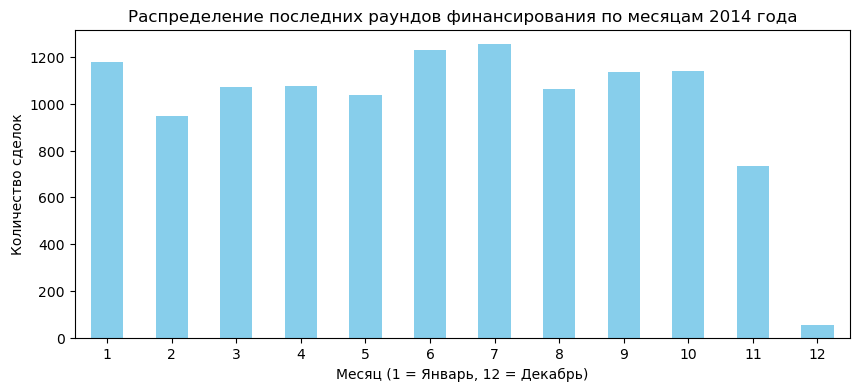

In [99]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
months_2014.plot(kind='bar', color='skyblue')
plt.title('Распределение последних раундов финансирования по месяцам 2014 года')
plt.xlabel('Месяц (1 = Январь, 12 = Декабрь)')
plt.ylabel('Количество сделок')
plt.xticks(rotation=0)
plt.show()

<b>Вывод:</b> Анализ распределения последних раундов по месяцам 2014 года показал, что данные за этот период неполные. С января по октябрь количество финансирования стабильно превышает <b>800</b>, однако в ноябре наблюдается резкий спад (<b>до 558 финансирований</b>), а в декабре количество раундов опускается до <b>37</b>. Это ограничение необходимо учитывать при дальнейшем анализе годовой динамики: снижение общего количества раундов в 2014 году может быть следствием неполноты данных за конец года, а не реальным падением инвестиционной активности на рынке.

Исключим из датасета компании, получившие аномальное финансирование

In [100]:
cb_investments_filtered = cb_investments_filtered[
    cb_investments_filtered['funding_total_usd'] <= cb_investments_filtered['upper_bound']
]

Мы оставили только те строки в датасете, значение которых в столбце `funding_total_usd` меньше или равно значению верхней границы.

Далее оставим в датасете данные только о тех компаниях, которые получали финансирование в годы, когда было зафиксировано 50 или более раундов финансирования

Выделим год финансирования из столбца `mid_year`

In [101]:
cb_investments_filtered['mid_funding_at'].dtype

dtype('<M8[ns]')

In [102]:
cb_investments_filtered['mid_year'] = cb_investments_filtered['mid_funding_at'].dt.year

Выведем данные столбца `mid_year` и проверим корректность извлечения года

In [103]:
cb_investments_filtered['mid_year']

1       2,014
2       2,009
3       2,013
4       2,014
7       2,014
         ... 
49430   2,014
49433   2,014
49434   2,014
49435   2,014
49437   2,014
Name: mid_year, Length: 35663, dtype: float64

Подсчитаем количество раундов по каждому году, для этого сгуппируем датасет по столбцу `funding_rounds`

In [104]:
rounds_per_year = cb_investments_filtered.groupby('mid_year')['funding_rounds'].sum()

Оставим данные только о тех годах, когда было совершено 50 и более раундов финансирования

In [105]:
valid_years = rounds_per_year[rounds_per_year >= 50].index

In [106]:
cb_investments_filtered = cb_investments_filtered.loc[cb_investments_filtered['mid_year'].isin(valid_years)]

###  Анализ типов финансирования по объёму и популярности

Построим график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Будем ориентироваться на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

In [107]:
total_funding_by_type = cb_investments_filtered[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                                                 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']].sum()

In [108]:
total_funding_by_type

seed                     9,431,331,895
venture                129,092,208,088
equity_crowdfunding        237,960,645
undisclosed              2,100,352,252
convertible_note           566,039,436
debt_financing           8,178,152,734
angel                    2,481,263,836
grant                    1,978,848,688
private_equity           4,843,108,504
post_ipo_equity          1,946,452,068
post_ipo_debt              286,718,349
secondary_market            45,285,796
product_crowdfunding       186,093,920
dtype: float64

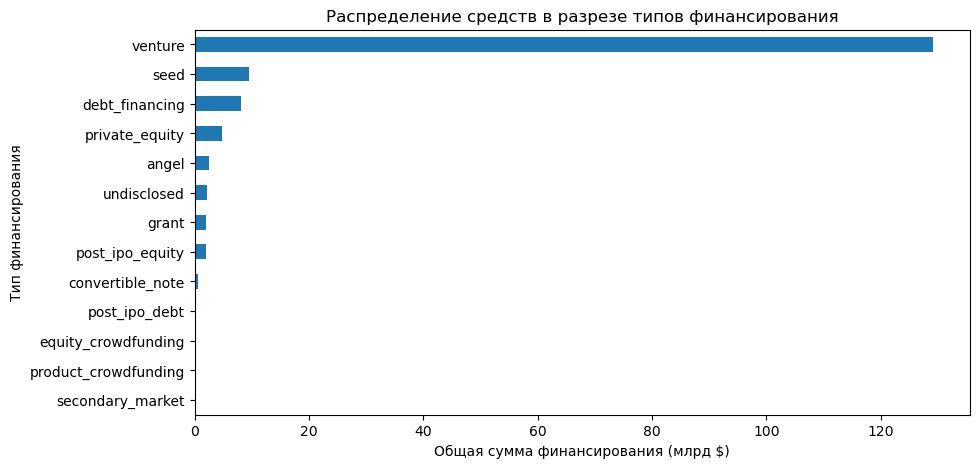

In [109]:
plt.figure(figsize=(10, 5))

(total_funding_by_type / 1_000_000_000).sort_values().plot(
    kind="barh", 
    legend=False, 
    title="Распределение средств в разрезе типов финансирования"
)

plt.xlabel('Общая сумма финансирования (млрд $)')
plt.ylabel('Тип финансирования')
plt.show()

Также построим график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

In [110]:
count_funding_by_type = (cb_investments_filtered[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                                                 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']] > 0).sum()

In [111]:
count_funding_by_type

seed                    13375
venture                 18820
equity_crowdfunding       515
undisclosed               813
convertible_note          521
debt_financing           3265
angel                    2937
grant                    1003
private_equity            634
post_ipo_equity           164
post_ipo_debt              27
secondary_market            7
product_crowdfunding      204
dtype: int64

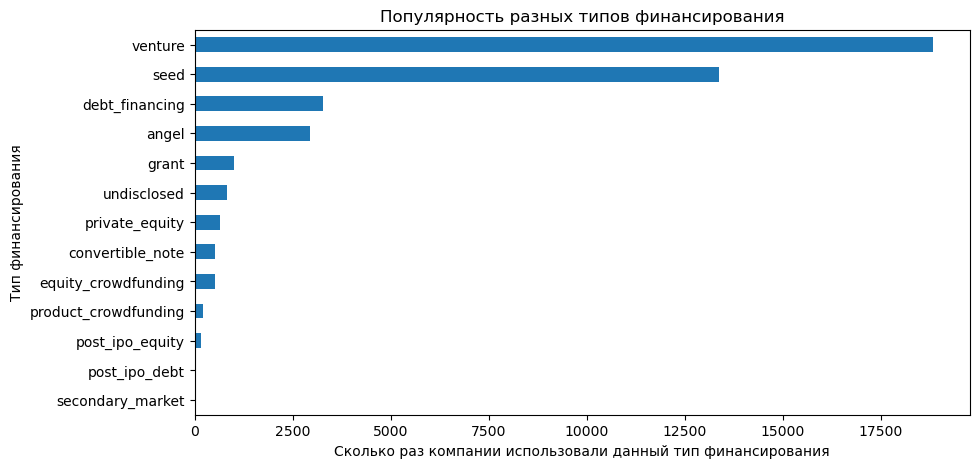

In [112]:
plt.figure(figsize=(10, 5))

(count_funding_by_type).sort_values().plot(
    kind="barh", 
    legend=False, 
    title="Популярность разных типов финансирования"
)

plt.xlabel('Сколько раз компании использовали данный тип финансирования')
plt.ylabel('Тип финансирования')
plt.show()

Сравним графики и выделим часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

Также при исследовании будем опираться на средний объема раунда для конкретного типа

In [113]:
avg_funding_per_round = total_funding_by_type / count_funding_by_type

In [114]:
avg_funding_per_round

seed                      705,146
venture                 6,859,310
equity_crowdfunding       462,060
undisclosed             2,583,459
convertible_note        1,086,448
debt_financing          2,504,794
angel                     844,829
grant                   1,972,930
private_equity          7,638,972
post_ipo_equity        11,868,610
post_ipo_debt          10,619,198
secondary_market        6,469,399
product_crowdfunding      912,225
dtype: float64

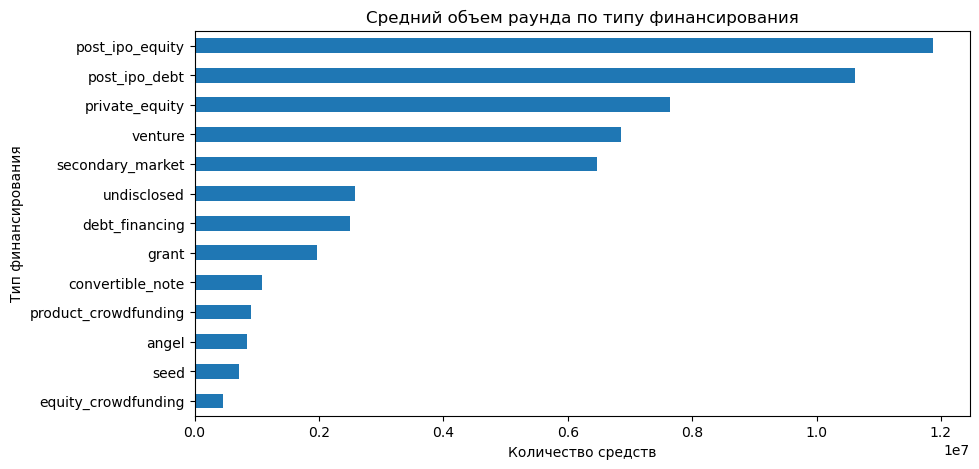

In [115]:
plt.figure(figsize=(10, 5))

(avg_funding_per_round).sort_values().plot(
    kind="barh", 
    legend=False, 
    title="Средний объем раунда по типу финансирования"
)

plt.xlabel('Количество средств')
plt.ylabel('Тип финансирования')
plt.show()

### Анализ структуры финансирования: объем, популярность и средний чек

Сравнение объемов привлеченных средств, частоты использования и среднего размера раунда по типам финансирования выявило три ключевых паттерна:

* **Безусловный лидер — venture.** Это самый популярный тип финансирования (18 869 упоминаний) и абсолютный лидер по привлеченным средствам (**131,2 млрд долларов**). Средний объем раунда составляет **6,9 млн долларов**. Данный тип нельзя отнести к категории малобюджетных: он характеризуется высоким уровнем вложений на одну сделку.

* **Массовый, но малобюджетный seed.** Занимает второе место как по популярности (13 378 компаний), так и по объему средств (**9,4 млрд долларов**). При этом средний размер раунда здесь минимален и составляет всего **705 тыс. долларов**. Это классический пример часто используемого инструмента с небольшими объемами вложений.

* **Редкий, но капиталоемкий post_ipo_equity.** В отличие от массовых типов, этот инструмент используется крайне редко (всего 172 упоминания), однако в общей сложности привлек **2,7 млрд долларов**. Он относится к категории редких, но значительных по объему предоставленных сумм финансирования.

Построим график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

In [116]:
total_funding_return = cb_returns[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                                                 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']].sum()

In [117]:
total_funding_return

seed                    2,382
venture                40,579
equity_crowdfunding         4
undisclosed               731
convertible_note           35
debt_financing          4,735
angel                   1,509
grant                       0
private_equity          3,587
post_ipo_equity         1,105
post_ipo_debt              91
secondary_market            5
product_crowdfunding        2
dtype: float64

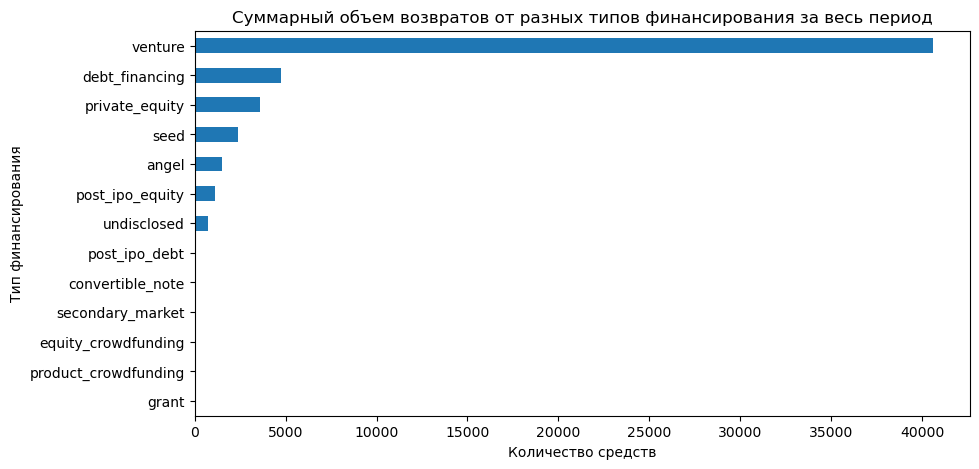

In [118]:
plt.figure(figsize=(10, 5))

(total_funding_return).sort_values().plot(
    kind="barh", 
    legend=False, 
    title="Суммарный объем возвратов от разных типов финансирования за весь период"
)

plt.xlabel('Количество средств')
plt.ylabel('Тип финансирования')
plt.show()

По данному графику видим, что тип финансирования `venture` продолжает являться лидером, количество возвращенных средств наибольшее. 

## Анализ динамики

### Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитаем для каждой компании средний объём одного раунда финансирования.

Для этого создадим датафрейм `company_round_stats` в который скопируем столбцы `name`, `funding_total_usd` и `funding_rounds`

In [119]:
company_round_stats = cb_investments_filtered[['name', 'funding_total_usd', 'funding_rounds']].copy()

В новый столбец `avg_round_size` датасета `company_round_stats` добавим рассчет среднего объема одного раунда финансирования. При этом заменим 0 в столбце `funding_rounds` на 1, чтобы избежать ошибки деления

In [120]:
company_round_stats['avg_round_size'] = company_round_stats['funding_total_usd'] / company_round_stats['funding_rounds'].replace(0,1)

На основе получившейся таблицы построим графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

In [121]:
company_round_stats['funding_year'] = cb_investments_filtered['mid_funding_at'].dt.year

In [122]:
typical_round_by_year = company_round_stats.groupby('funding_year')['avg_round_size'].median()

In [123]:
typical_round_by_year

funding_year
2000   2,250,000
2001   1,570,886
2002   3,225,000
2003   1,500,000
2004   3,000,000
2005   4,500,000
2006   3,900,000
2007   2,879,167
2008   2,170,744
2009   1,498,475
2010   1,250,000
2011     867,685
2012     686,000
2013     559,000
2014     560,625
Name: avg_round_size, dtype: float64

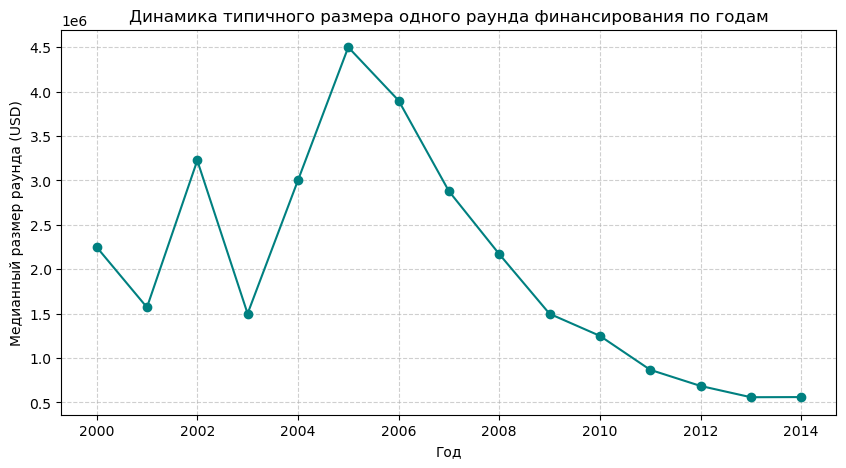

In [124]:
plt.figure(figsize=(10, 5))

typical_round_by_year.plot(kind='line', marker='o', color='teal')
plt.title('Динамика типичного размера одного раунда финансирования по годам')
plt.xlabel('Год')
plt.ylabel('Медианный размер раунда (USD)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [125]:
rounds_activity_by_year = company_round_stats.groupby('funding_year')['funding_rounds'].sum()


In [126]:
rounds_activity_by_year

funding_year
2000      113
2001       66
2002       98
2003      125
2004      181
2005      948
2006    1,849
2007    2,842
2008    3,663
2009    4,617
2010    6,136
2011    7,578
2012    9,707
2013   12,880
2014    7,122
Name: funding_rounds, dtype: float64

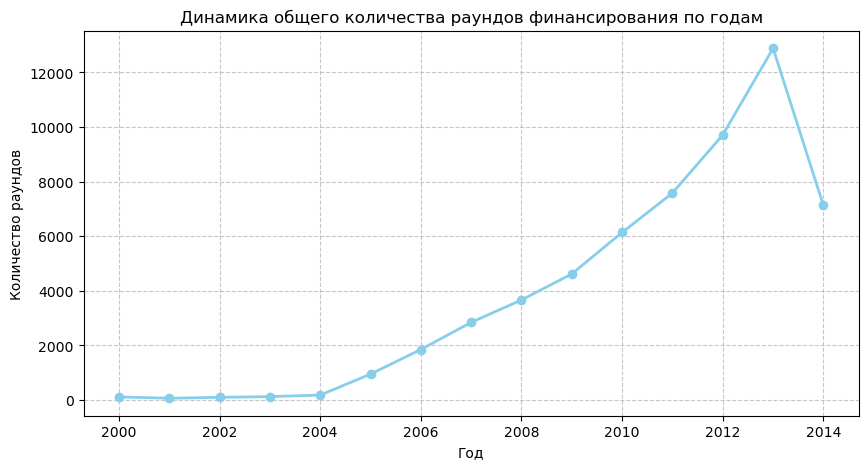

In [127]:
plt.figure(figsize=(10, 5))

rounds_activity_by_year.plot(kind='line', marker='o', color='skyblue', linewidth=2)

plt.title('Динамика общего количества раундов финансирования по годам')
plt.xlabel('Год')
plt.ylabel('Количество раундов')

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

На основе полученных данных можем сделать следующие выводы:
* В 2005 году типичный размер средств, собранных в рамках одного раунда, был максимальным и составлял 4 500 000 долларов

* В 2014 году наблюдалась следующая тенденция по количеству раундов и средств, выделяемых в рамках каждого раунда: спад количества раундов финансирования по сравнению с предыдущими годами, с 2004 наблюдался рост, незначительный подъем типичного размера одного раунда финансирования, спад с 2005 года

### Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составим сводную таблицу, в которой укажем суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберем из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

In [128]:
pivot_funding = cb_investments_filtered.groupby(['mid_year', 'market'])['funding_total_usd'].sum().unstack(level=0).fillna(0)

In [129]:
pivot_funding

mid_year,"2,000","2,001","2,002","2,003","2,004","2,005","2,006","2,007","2,008","2,009","2,010","2,011","2,012","2,013","2,014"
market,,,,,,,,,,,,,,,
advertising,"14,470,000","8,778,321","24,500,000","10,500,000","6,000,000","127,196,022","299,299,458","556,704,331","622,673,464","563,446,005","631,617,869","410,730,737","521,137,032","524,915,135","207,792,333"
analytics,"14,822,803",0,"7,500,000","3,840,000","3,000,000","79,014,044","139,701,311","98,829,000","208,077,840","140,949,327","253,739,903","443,333,373","539,214,309","622,821,367","151,461,613"
apps,0,0,0,0,0,0,"1,310,600",0,"4,300,000","7,219,000","6,123,779","18,374,071","32,601,125","28,868,621","66,237,730"
automotive,0,0,0,"4,530,000",0,"22,500,000","12,660,000","37,712,601","59,478,635","20,800,311","17,696,916","76,452,163","35,557,677","117,572,526","69,034,162"
big data,0,0,0,0,0,0,0,"7,780,000","2,452,515","597,375","39,233,297","60,369,158","86,413,341","78,698,922","79,232,600"
biotechnology,0,0,0,"85,531,178","97,184,859","480,063,583","903,500,543","1,704,078,338","1,716,033,000","3,915,900,521","4,894,500,078","4,967,551,850","4,931,138,800","5,694,269,809","2,509,638,562"
clean technology,0,0,"34,390,435","50,352,939","50,427,954","19,420,000","131,473,889","749,711,239","3,165,808,492","1,963,502,838","1,604,429,454","1,545,603,337","958,011,189","1,203,060,535","688,686,785"
cloud computing,"11,500,000",0,0,0,0,0,"9,951,809","20,354,343","44,375,000","52,223,719","8,525,538","73,151,398","74,421,582","84,846,778","73,440,856"
consulting,"4,500,000",0,0,0,0,"44,862,000","23,965,548","70,346,345","19,061,080","62,715,165","81,264,877","43,413,397","65,922,756","93,321,324","54,298,022"


Отберем только те сегменты, которые показали рост объема финансирования с 2013 по 2014 годы

In [130]:
growing_segments = pivot_funding[pivot_funding[2014] > pivot_funding[2013]]
growing_segments[[2013, 2014]]

mid_year,"2,013","2,014"
market,,
apps,"28,868,621","66,237,730"
big data,"78,698,922","79,232,600"
design,"60,958,835","68,988,516"
internet,"69,732,096","117,830,756"
manufacturing,"393,936,634","416,332,314"
medical,"64,469,424","175,236,064"
mid,"1,686,905,096","1,868,755,421"
niche,"269,904,287","738,172,920"
real estate,"92,207,655","115,567,364"


In [131]:
growing_segments[2014] - growing_segments[2013]

market
apps             37,369,109
big data            533,678
design            8,029,681
internet         48,098,660
manufacturing    22,395,680
medical         110,766,640
mid             181,850,325
niche           468,268,633
real estate      23,359,709
saas             13,231,139
startups         23,421,285
technology       81,145,050
без категории   350,064,523
dtype: float64

На графике отразим, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у нас достаточно данных. Будем рассматривать только массовые сегменты, а средние и нишевые исключим.

Построим график с динамикой суммарного финансирования в растущих массовых сегментах

In [132]:
mass_segments_list = cb_investments_filtered.loc[
    (cb_investments_filtered['market'] != 'mid') & 
    (cb_investments_filtered['market'] != 'niche'), 
    'market' 
].unique()

In [133]:
growing_mass_segments = growing_segments[
    growing_segments.index.isin(mass_segments_list)
]

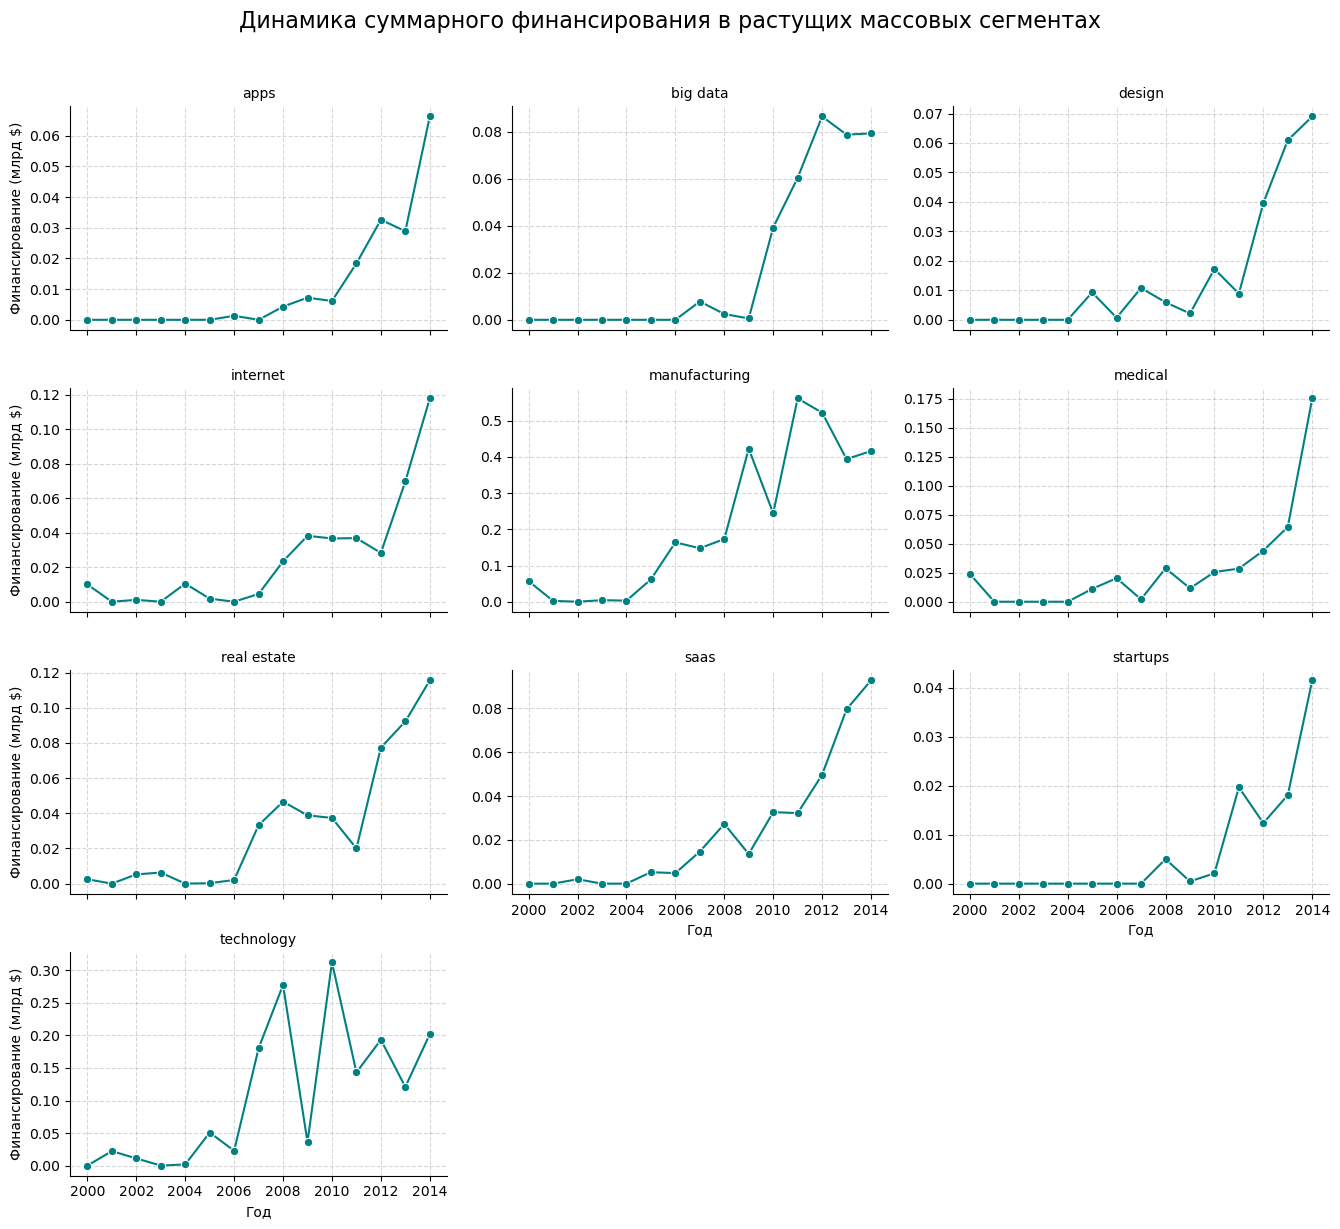

In [134]:
growing_mass_segments_clean = growing_mass_segments.drop('без категории', errors='ignore')

plot_data = growing_mass_segments_clean.T
plot_data.index.name = 'year'
plot_data = plot_data.reset_index()
plot_data_long = plot_data.melt(id_vars='year', var_name='segment', value_name='funding')
plot_data_long['funding'] = plot_data_long['funding'] / 1_000_000_000

g = sns.FacetGrid(plot_data_long, col="segment", col_wrap=3, height=3, aspect=1.5, sharey=False)

g.map(sns.lineplot, "year", "funding", color="teal", marker='o')

g.set_titles(col_template="{col_name}")
g.set_axis_labels("Год", "Финансирование (млрд $)")
g.fig.suptitle('Динамика суммарного финансирования в растущих массовых сегментах', y=1.02, fontsize=16)

for ax in g.axes.flatten():
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Вывод: По динамике суммарного финансирования в растущих массовых сегментах можно выделить несколько типов роста:

* Наиболее быстрый и уверенный рост демонстрирует сегмент `medical`. С 2011 года объем финансирования в нем вырос в разы, а в 2014 году было привлечено на 110 766 640 долларов больше, чем в 2013. Схожая взрывная динамика наблюдается у сегмента `apps`: с 2010 года на графике виден резкий восходящий тренд, и в 2014 году прирост составил 37 369 109 долларов.

* Стабильный последовательный рост (без резких скачков) характерен для сегментов `internet` (прирост на 48 098 660 долларов к 2014 году) и `saas` (прирост на 13 231 139 долларов). В них наблюдается плавное увеличение объемов из года в год.

* Сегмент `manufacturing` также показывает уверенный восходящий тренд, однако его график отличается высокой волатильностью: за резким пиком в 2012 году последовал спад, после чего объемы снова начали расти (прирост в 2014 году — 22 395 680 долларов).

Таким образом, наиболее уверенный и быстрый рост демонстрируют сегменты `medical` и `apps`, а также `internet`, в то время как остальные сегменты показывают либо более скромный прирост, либо выраженную цикличность.


### Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Поэтому для каждого года и каждого вида финансирования рассчитаем нормированные значения возврата средств. При этом слишком большие аномальные значения, то есть неадекватные выбросы, заменим на пропуски.

In [135]:
investment_cols = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note',
    'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity',
    'post_ipo_debt', 'secondary_market', 'product_crowdfunding'
]

In [136]:
investments_by_year = cb_investments_filtered.groupby('mid_year')[investment_cols].sum()

In [137]:
returns_by_year = cb_returns[investment_cols] * 1_000_000

In [138]:
common_years = investments_by_year.index.intersection(returns_by_year.index)

In [139]:
return_ratio = (returns_by_year.loc[common_years] / (investments_by_year.loc[common_years] + 1e-60)) * 100

In [140]:
return_ratio = return_ratio.mask(return_ratio > 1000)

In [141]:
return_ratio.round(2)

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
2000,100,17,0,70,0,62,27,0,0,27,0,3,0
2001,108,11,0,59,1,77,118,0,0,NaN,0,NaN,0
2002,63,68,0,61,NaN,22,114,0,20,113,0,NaN,0
2003,51,63,0,91,NaN,104,61,0,NaN,NaN,0,NaN,0
2004,55,84,0,53,NaN,44,83,0,NaN,NaN,0,NaN,0
2005,67,55,0,107,NaN,34,51,0,48,73,0,NaN,0
2006,93,34,20,76,17,80,67,0,94,NaN,0,NaN,0
2007,37,30,NaN,50,23,60,82,0,58,203,0,NaN,0
2008,30,19,NaN,34,6,93,41,0,68,234,0,NaN,0
2009,56,17,9,38,5,39,62,0,79,210,0,1,7


Построим график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

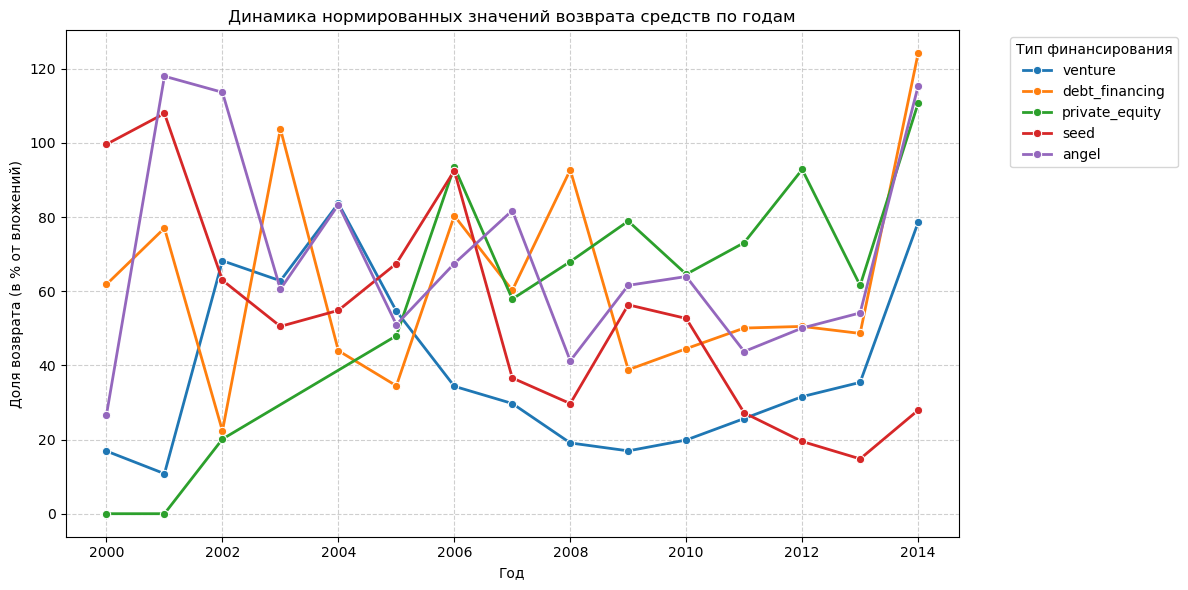

In [142]:
selected_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']
plot_data = return_ratio[selected_types]

plt.figure(figsize=(12, 6))
sns.lineplot(data=plot_data, dashes=False, linewidth=2, marker='o')
plt.title('Динамика нормированных значений возврата средств по годам')
plt.xlabel('Год')
plt.ylabel('Доля возврата (в % от вложений)')
plt.legend(title='Тип финансирования', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Сделаем вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

Вывод: На графике не наблюдается ни одного типа финансирования с абсолютно устойчивым ростом — для всех характерны резкие взлеты и падения. Наибольшая волатильность свойственна `angel` и `debt_financing`, которые показывают самые глубокие провалы и высокие пики. При этом `seed` демонстрирует общий нисходящий тренд (от пика в 2001 году к спаду в 2013-м), тогда как `venture` и `private_equity` отличаются более сглаженной цикличностью. Единственный общий паттерн — синхронный подъем показателей у большинства типов к 2014 году.


### Итоговый вывод и рекомендации

#### Общий обзор проделанной работы
В ходе проекта были выполнены следующие шаги:
* Предобработка данных: Привели названия столбцов к стилю snake_case, обработали типы данных (включая перевод дат в формат `datetime`), избавились от полных дубликатов и удалили строки без информации о финансировании. Восстановили пропуски в дате `mid_funding_at` и заменили пропуски в отраслях на заглушки.
* Инжиниринг признаков: Разделили компании на группы по срокам финансирования (единичное, до года, более года) и классифицировали сегменты рынка на массовые, средние и нишевые.
* Работа с выбросами и анализ: Определили аномальные объемы финансирования с помощью метода IQR для каждого сегмента отдельно. Очистили датасет от выбросов и ограничили период исследования годами, где было зафиксировано 50 и более раундов.
* Исследование динамики и доходности: Проанализировали популярность и объёмы разных типов финансирования, рассчитали медианный размер раунда, а также нормированные значения возврата средств (ROI) по годам.


#### Главные выводы (ответы на исследовательские вопросы)
* Структура рынка и аномалии. Аномально крупные раунды — это системная особенность рынка (их доля в топ-15 сегментах стабильно держится на уровне 10–15%), а не специфика одной отрасли. Лидерами по абсолютному числу аномалий являются сегменты `software` и `mid`.
* Популярность и объёмы финансирования. Абсолютным лидером как по объёму привлеченных средств (131,2 млрд долларов), так и по популярности (18 869 упоминаний) является тип `venture`. При этом `seed` — это массовый инструмент (13 378 компаний) с самым маленьким средним чеком (705 тыс. долларов), а `post_ipo_equity` — редкий, но капиталоемкий тип.
* Динамика рынка. Типичный размер раунда достиг своего пика в 2005 году (4,5 млн долларов), после чего наблюдался спад. Общая активность инвесторов (количество раундов) росла с 2004 года вплоть до 2013-го, однако в 2014 году наметился спад активности при одновременном незначительном росте типичного размера раунда.
* Доходность (возврат средств). Ни один из типов финансирования не показывает абсолютно устойчивого роста возврата средств. Наибольшая волатильность свойственна `angel` и `debt_financing`. Тип `seed` демонстрирует общий нисходящий тренд окупаемости, а `venture` и `private_equity` отличаются сглаженной цикличностью.


#### Рекомендации для инвестора

1. В какую отрасль стоит инвестировать?

Рекомендуется сосредоточиться на массовых сегментах рынка, которые продемонстрировали фактический рост объемов финансирования в 2014 году по сравнению с 2013-м. Согласно проведенному анализу динамики, к таким сегментам относятся:

* `medical` (прирост на 110,7 млн долларов) и `apps` (прирост на 37,3 млн долларов) — эти сегменты показали наиболее взрывной и уверенный рост на графиках.

* `internet` (прирост на 48,1 млн долларов) и `saas` (прирост на 13,2 млн долларов) — демонстрируют стабильный последовательный рост из года в год.

Вкладываться в сегменты, которые в 2014 году показали снижение (например, `software`, `e-commerce` или `mobile`), на фоне общего оживления рынка нецелесообразно. Также следует избегать узких нишевых сегментов из-за малого объема выборки и, как следствие, высокой волатильности.


2. Какой тип финансирования будет наиболее уместным?
Для выхода на рынок с покупкой и развитием компаний наиболее уместно использовать венчурное финансирование (`venture`). 
Это обосновано тем, что:
*   Это самый емкий рынок (131,2 млрд долларов вложений).
*   Он обладает высокой популярностью и инфраструктурой.
*   Средний чек в этом сегменте (6,9 млн долларов) является сбалансированным — он достаточно велик для масштабирования бизнеса, но не требует таких колоссальных вливаний, как `private_equity` (8,8 млн долларов) или `post_ipo_equity` (15,7 млн долларов).
*   Несмотря на волатильность, к 2014 году доходность `venture` показала один из самых сильных скачков (рост до 75%), что говорит о высоком потенциале возврата инвестиций на фоне общего оживления рынка.
